Label-noise robustness SVM

In [1]:
import json
import pickle
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.svm import LinearSVC

SEED = 42
NOISE_RATE = 0.10

SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")
WEIGHTS_DIR = Path("../../weights/noise10/svm")
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("../../../results/svm")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(SPLITS_DIR / "noise10" / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")  # original, unmodified — never touch val/test labels

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)
LABEL_ORDER = list(label_encoder.classes_)

y_train = label_encoder.transform(train_df["category"])  # noisy labels, by design
y_val = label_encoder.transform(val_df["category"])

print("Train (noisy) rows:", len(train_df), "| flipped:", int(train_df["is_flipped"].sum()))
print("Val (clean) rows:", len(val_df))

Train (noisy) rows: 50000 | flipped: 5000
Val (clean) rows: 48178


In [2]:
MAX_FEATURES = 50000
NGRAM_RANGE = (1, 2)
MIN_DF = 2
SUBLINEAR_TF = True
C = 1.0

vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES, ngram_range=NGRAM_RANGE, min_df=MIN_DF, sublinear_tf=SUBLINEAR_TF
)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])

model = LinearSVC(C=C, random_state=SEED)
start_time = time.time()
model.fit(X_train, y_train)
train_time_sec = time.time() - start_time
print(f"Training took {train_time_sec:.1f}s")

Training took 8.9s


               precision    recall  f1-score   support

     Business       0.79      0.73      0.76      6323
Entertainment       0.78      0.86      0.82     12064
       Health       0.70      0.69      0.69      4196
     Politics       0.76      0.75      0.76      6238
      Science       0.66      0.49      0.56      1609
       Sports       0.89      0.90      0.89      5854
   Technology       0.79      0.77      0.78      5828
        World       0.80      0.78      0.79      6066

     accuracy                           0.79     48178
    macro avg       0.77      0.75      0.76     48178
 weighted avg       0.79      0.79      0.78     48178

Val accuracy: 0.7862
Inference time: 0.03s total, 0.001 ms/sample

SVM_a in-distribution test accuracy for comparison: 0.8381 (see results/svm/SVM_a_metrics.json)


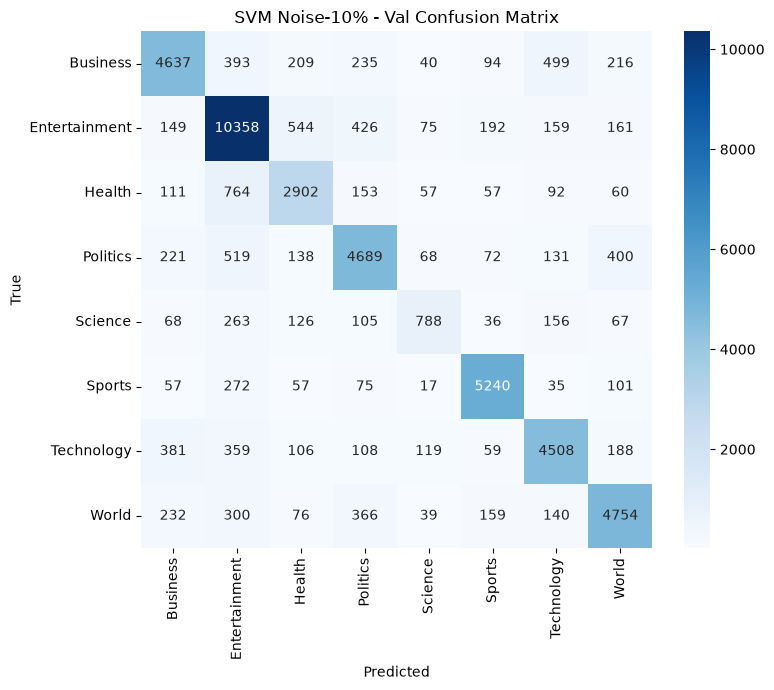

In [3]:
inf_start = time.time()
y_pred = model.predict(X_val)
inf_time_sec = time.time() - inf_start

report_dict = classification_report(y_val, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0)
print(classification_report(y_val, y_pred, target_names=LABEL_ORDER, zero_division=0))

val_accuracy = report_dict["accuracy"]
print(f"Val accuracy: {val_accuracy:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(val_df) * 1000:.3f} ms/sample")
print("\nSVM_a in-distribution test accuracy for comparison: 0.8381 (see results/svm/SVM_a_metrics.json)")

cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM Noise-10% - Val Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "svm_noise10_confusion_matrix.png", dpi=150)
plt.show()
plt.close()

In [4]:
with open(WEIGHTS_DIR / "svm_model.pkl", "wb") as f:
    pickle.dump(model, f)
with open(WEIGHTS_DIR / "vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

config = {
    "max_features": MAX_FEATURES,
    "ngram_range": list(NGRAM_RANGE),
    "min_df": MIN_DF,
    "sublinear_tf": SUBLINEAR_TF,
    "C": C,
}
with open(WEIGHTS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

metrics = {
    "model_family": "svm",
    "model_name": "linear-svm-tfidf-noise10",
    "run_timestamp": datetime.now(timezone.utc).isoformat(),
    "label_order": LABEL_ORDER,
    "noise_rate": NOISE_RATE,
    "config": config,
    "train": {
        "n_train": len(train_df),
        "n_flipped": int(train_df["is_flipped"].sum()),
        "train_time_sec": train_time_sec,
    },
    "test": {
        "n_test": len(val_df),
        "eval_split": "val (original, unmodified)",
        "accuracy": float(val_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(val_df) * 1000,
    },
    "environment": {
        "framework": "scikit-learn",
        "framework_version": sklearn.__version__,
        "device": "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "svm_noise10_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:")
print(" ", WEIGHTS_DIR / "svm_model.pkl")
print(" ", WEIGHTS_DIR / "vectorizer.pkl")
print(" ", WEIGHTS_DIR / "config.json")
print(" ", RESULTS_DIR / "svm_noise10_metrics.json")
print(" ", RESULTS_DIR / "svm_noise10_confusion_matrix.png")

Saved:
  ..\..\weights\noise10\svm\svm_model.pkl
  ..\..\weights\noise10\svm\vectorizer.pkl
  ..\..\weights\noise10\svm\config.json
  ..\..\..\results\svm\svm_noise10_metrics.json
  ..\..\..\results\svm\svm_noise10_confusion_matrix.png
